# LAB 11 : Decision Tree Classification Using Iris Dataset

Task 1: Data Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

# Load dataset and separate feature matrix from target vector
iris_raw = load_iris()
petal_sepal_X = iris_raw.data
species_y = iris_raw.target
attr_names = iris_raw.feature_names
class_labels = iris_raw.target_names

print(f"Input features shape: {petal_sepal_X.shape}")
print(f"Target labels shape : {species_y.shape}")
print(f"Species classes     : {list(class_labels)}")

Input features shape: (150, 4)
Target labels shape : (150,)
Species classes     : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(
    petal_sepal_X,
    species_y,
    test_size=0.20,
    random_state=42
)

print(f"Training set size: {len(X_tr)} samples")
print(f"Testing set size : {len(X_te)} samples")

Training set size: 120 samples
Testing set size : 30 samples


Task 2: Decision Tree Model Development

In [3]:
tree_clf = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

# Fit classifier on training split and predict on test split
tree_clf.fit(X_tr, y_tr)
y_pred_tree = tree_clf.predict(X_te)

preview_df = pd.DataFrame({
    "Actual Species": [class_labels[i] for i in y_te[:8]],
    "Predicted Species": [class_labels[i] for i in y_pred_tree[:8]]
})
print("First 8 Test Predictions:")
print(preview_df.to_string(index=False))

First 8 Test Predictions:
Actual Species Predicted Species
    versicolor        versicolor
        setosa            setosa
     virginica         virginica
    versicolor        versicolor
    versicolor        versicolor
        setosa            setosa
    versicolor        versicolor
     virginica         virginica


Task 3: Decision Tree Visualization

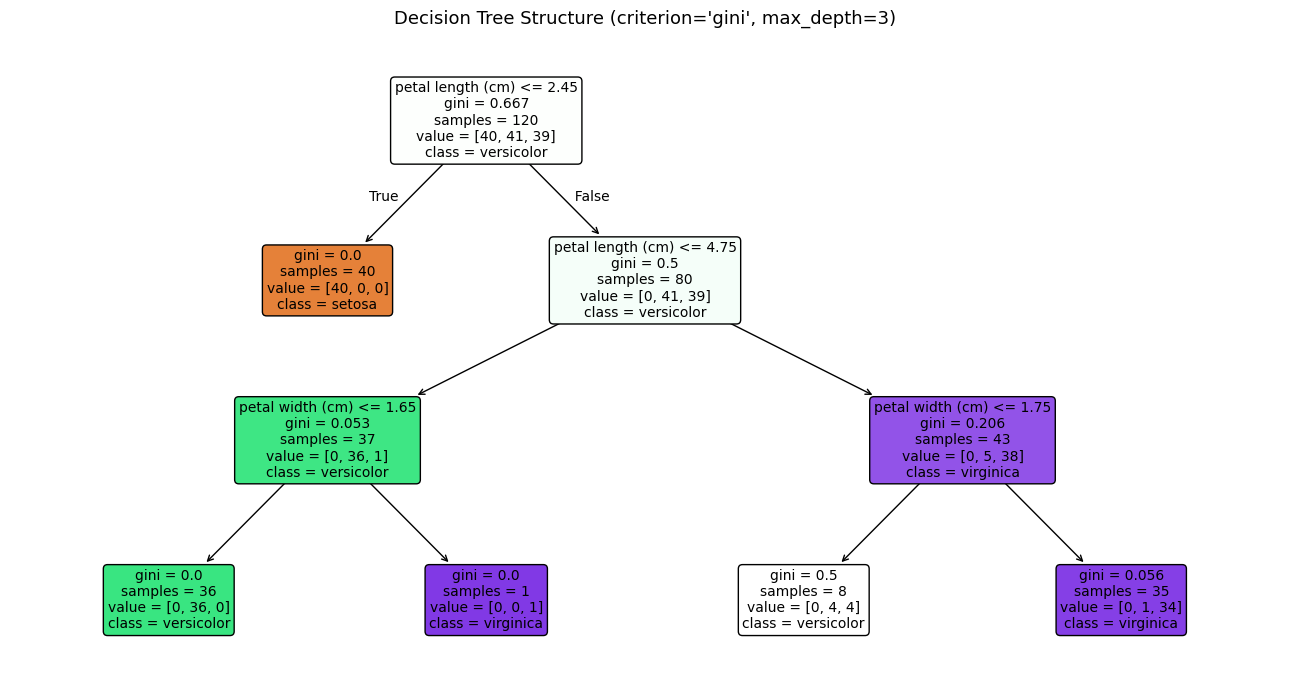

In [4]:
fig, ax = plt.subplots(figsize=(13, 7))
plot_tree(
    tree_clf,
    feature_names=attr_names,
    class_names=class_labels,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax
)
ax.set_title("Decision Tree Structure (criterion='gini', max_depth=3)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

Task 4: Performance Evaluation

In [5]:
acc_depth3 = accuracy_score(y_te, y_pred_tree)
print(f"Decision Tree Testing Accuracy: {acc_depth3 * 100:.2f}%\n")

cm_array = confusion_matrix(y_te, y_pred_tree)
cm_table = pd.DataFrame(
    cm_array,
    index=[f"True_{cls}" for cls in class_labels],
    columns=[f"Pred_{cls}" for cls in class_labels]
)
print("Confusion Matrix:")
print(cm_table)

Decision Tree Testing Accuracy: 100.00%

Confusion Matrix:
                 Pred_setosa  Pred_versicolor  Pred_virginica
True_setosa               10                0               0
True_versicolor            0                9               0
True_virginica             0                0              11


In [6]:
w_precision, w_recall, w_f1, _ = precision_recall_fscore_support(
    y_te,
    y_pred_tree,
    average="weighted"
)

print(f"Weighted Precision : {w_precision:.4f}")
print(f"Weighted Recall    : {w_recall:.4f}")
print(f"Weighted F1-Score  : {w_f1:.4f}\n")

print("Per-Class Classification Report:")
print(classification_report(y_te, y_pred_tree, target_names=class_labels))

Weighted Precision : 1.0000
Weighted Recall    : 1.0000
Weighted F1-Score  : 1.0000

Per-Class Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Feature Importance Scores:
     Feature Name  Gini Importance
petal length (cm)         0.934626
 petal width (cm)         0.065374
 sepal width (cm)         0.000000
sepal length (cm)         0.000000


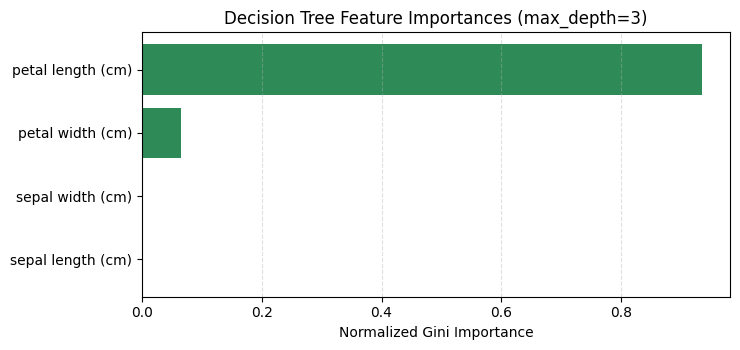

In [7]:
feat_imp_table = pd.DataFrame({
    "Feature Name": attr_names,
    "Gini Importance": tree_clf.feature_importances_
}).sort_values(by="Gini Importance", ascending=False).reset_index(drop=True)

print("Feature Importance Scores:")
print(feat_imp_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(feat_imp_table["Feature Name"][::-1], feat_imp_table["Gini Importance"][::-1], color="#2e8b57")
ax.set_xlabel("Normalized Gini Importance")
ax.set_title("Decision Tree Feature Importances (max_depth=3)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Task 5: Comparative Analysis

In [8]:
depth_settings = [2, 3, 5]
depth_results = []

for depth_val in depth_settings:
    temp_tree = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth_val,
        random_state=42
    )
    temp_tree.fit(X_tr, y_tr)

    train_acc = accuracy_score(y_tr, temp_tree.predict(X_tr))
    test_acc = accuracy_score(y_te, temp_tree.predict(X_te))

    depth_results.append({
        "Model": f"Decision Tree (Depth = {depth_val})",
        "Testing Accuracy": f"{test_acc * 100:.2f}% ({test_acc:.4f})",
        "_train_acc": f"{train_acc * 100:.2f}%"
    })

# Display the exact comparison table requested in Task 5
final_comparison = pd.DataFrame(depth_results)[["Model", "Testing Accuracy"]]
print(final_comparison.to_string(index=False))

                    Model Testing Accuracy
Decision Tree (Depth = 2)  96.67% (0.9667)
Decision Tree (Depth = 3) 100.00% (1.0000)
Decision Tree (Depth = 5) 100.00% (1.0000)
